# Contextual Lexical-Stress Prediction for Bulgarian TTS from Dictionary-Marked Text and Stress-Aware Forced Alignment

**A reproduction and extension of the Accentor front-end (Geneva et al., Interspeech 2023), integrated into a diffusion-LM TTS (OmniVoice)**

*Draft paper foundation — OmniVoice-BG project, 2026. All tables and figures in this notebook regenerate from the repository's real experiment artifacts.*

---

## Abstract *(draft)*

Bulgarian lexical stress is phonemic, mobile, and unmarked in orthography; roughly 1 in 23 word forms is a stress **homograph** (въ́лна *wool* / вълна́ *wave*), and ~34% of utterances contain at least one. Dictionary lookup cannot resolve homographs, and synthetic-speech oracles systematically fail on them. We reproduce the Accentor architecture — a character-level FFT-block network that marks the stressed vowel of every word in context — and train it **without any manually stress-annotated sentences**, using two label sources: (i) dictionary-marked text with homographs masked from the loss (pretrain, 80M tokens), and (ii) per-token stress choices decoded from human speech by a stress-aware Kaldi forced aligner over audiobooks and parliamentary recordings (fine-tune). A native-speaker vetting protocol calibrates a three-tier label-acceptance policy that neutralizes a systematic final-stress bias we identify in GMM alignment. We further introduce rule-assisted *both-readings* text mining for the morphologically regular imperative/3sg alternation. The resulting model reaches **0.002% stress-error rate** on held-out single-stress words and **0.014–0.021% out-of-domain SER** on parliamentary stenograms, with homograph-battery accuracy improving from 11/25 (text-only) to 13/25 and both readings of the highest-coverage homograph classes resolved contextually. We report empirical *coverage walls* for homograph learning — a ~20-distinct-contexts threshold per reading, an absolute-count (not class-ratio) wall for imperatives, and a demonstration that sparse noisy minority labels *invert* classes — and integrate the front-end into OmniVoice-BG, showing that TTS stress control requires the acoustic model to be fine-tuned on the *same* marking function it sees at inference.

> **TODO before submission:** exact bibliographic entries (§References), final OOD numbers after the milestone-A data lands, MOS/listening-test protocol for §8.


## Contents

1. [Introduction](#1.-Introduction)
2. [Background and related work](#2.-Background-and-related-work)
3. [System overview: a three-model relay](#3.-System-overview:-a-three-model-relay)
4. [Data](#4.-Data)
5. [Method](#5.-Method)
6. [Experiments and results](#6.-Experiments-and-results)
7. [Findings](#7.-Findings)
8. [End-to-end TTS evaluation](#8.-End-to-end-TTS-evaluation)
9. [Limitations](#9.-Limitations)
10. [Future work](#10.-Future-work)
11. [Reproducibility](#11.-Reproducibility)
12. [References](#12.-References)


In [1]:
# Setup — all paths resolve relative to the repo root (notebook lives in docs/)
import json, os, sys, sqlite3, collections, random
from pathlib import Path

ROOT = Path('.') if Path('exp').exists() else Path('..')
assert (ROOT / 'accentor_model.py').exists(), 'run from the OmniVoice repo (or docs/)'

def jload(path, limit=None):
    "Read a JSONL file -> list of dicts (optionally first `limit` rows)."
    rows = []
    with open(ROOT / path, encoding='utf-8') as f:
        for i, line in enumerate(f):
            if limit and i >= limit: break
            line = line.strip()
            if line: rows.append(json.loads(line))
    return rows

def exists(path): return (ROOT / path).exists()

import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['figure.dpi'] = 110
print('repo root:', ROOT.resolve())

repo root: /home/preslaff/WORK/OmniVoice


## 1. Introduction

Bulgarian word stress is **lexical** (a property of the word, not the phrase), **mobile** (it moves within inflectional paradigms: чета́ *I read* → че́теш *you read*), **phonemic** (it distinguishes meanings), and **orthographically unmarked**. For a text-to-speech system this is the single hardest front-end problem in the language: the correct output depends on information that is simply not in the input string.

Three failure classes motivate this work, in increasing order of difficulty:

1. **Unknown words.** A TTS model with no stress knowledge guesses — *БУтона* for *буто́на*, *натИснете* for *натисне́те*. A pronunciation dictionary solves this for in-vocabulary words.
2. **Out-of-vocabulary inflections.** Bulgarian inflection is rich; a lemma dictionary must be *projected* onto ~2.5M inflected forms, with morphophonological rules for stress-shifting paradigms.
3. **Homographs.** Pairs like въ́лна/вълна́ (*wool/wave*), че́та/чета́ (*detachment/I read*), гово́ри/говори́ (*speaks/speak!*) are identical strings whose stress depends on **sentence context**. No dictionary can resolve them. Per Geneva et al., ~4.3% of Bulgarian word forms are stress-ambiguous and ~34% of utterances contain at least one.

The Accentor approach (Geneva et al., Interspeech 2023) treats stress placement as a **sequence-labeling problem over characters**: a lightweight network reads the whole sentence and emits, for every vowel, the probability that it carries its word's stress. Crucially, its training labels for ambiguous words can be manufactured **from speech** — a stress-aware forced aligner, given both possible pronunciations of a homograph, decodes *which one the human actually said* — so no manual sentence-level stress annotation is ever needed.

This notebook documents a full reproduction of that recipe for a production Bulgarian TTS (OmniVoice-BG), plus what we learned that the original paper does not report.

### Contributions

- **C1 — A fully open, reproducible pipeline** from raw dictionary dump + book archive + parliamentary video API to a deployed contextual stress front-end, with no manually stress-annotated training sentences anywhere in the loop.
- **C2 — A recall-oriented multi-stress candidates lexicon** (2.16M candidate pronunciations; 84K ambiguous forms) built from the *rechko* dictionary, with a native-curated homograph battery and an always-final imperative override table correcting systematic dictionary errors.
- **C3 — A vetting-calibrated three-tier label policy** for alignment-derived stress labels, motivated by a systematic **final-stress bias** we identify in GMM forced alignment on prosodically weak words — strong enough to invert corpus majorities (може́ counted 1125:517 against the true мо́же).
- **C4 — Rule-assisted *both-readings* text mining** for the morphologically regular imperative/3sg alternation, which supplements speech labels for the register-starved imperative class at ~96% precision.
- **C5 — Empirical coverage laws for homograph learning:** a ~20-distinct-contexts-per-reading threshold; an *absolute-count* (not class-ratio) wall for imperfective imperatives; and a demonstration that sparse noisy minority labels can *invert* a class ("a little noisy data is worse than none").
- **C6 — End-to-end TTS integration** into a mask-prediction diffusion LM (OmniVoice), establishing the *marking-consistency principle*: the acoustic model must be fine-tuned on text marked by the same front-end version used at inference, or the mark→stress mapping it learns is noise.


## 2. Background and related work

**The Accentor (Geneva et al., Interspeech 2023).** The reference work. A character-level model (embedding + 6 FastSpeech-style FFT blocks + convolutional predictor, ~6.5M params with depthwise-separable convolutions) predicts per-vowel stress probabilities, trained with per-vowel BCE. Labels come from two sources: an authoritative stress dictionary for unambiguous words, and forced alignment of 749 h of speech (audiobooks + the BG-PARLAMA parliamentary corpus, 2,695 aligned hours) with a stressed/unstressed vowel phone set for ambiguous words. Reported stress-error rates: 0.119% (automatic) / 0.37% (manual evaluation).

**BG-PARLAMA.** Geneva et al.'s parliamentary speech corpus, built by aligning plenary-session video against the official stenographic transcripts. Our stage-4 crawl reproduces this resource from the same public source (parliament.bg pl-sten API), 2020–2026 sessions.

**Parliament-speech alignment pipelines.** Our long-audio segmentation follows the Kaldi `segment_long_utterances` recipe family used by the Finnish Parliament ASR corpus (Virkkunen et al., arXiv:2203.14876), which is the closest published engineering reference for transcript-biased decoding of plenary recordings.

**OmniVoice.** A massively multilingual zero-shot TTS: a Qwen3-0.6B text-LLM backbone repurposed to predict Higgs Audio V2 codec tokens (8 codebooks, 24 kHz) under a mask-prediction / iterative-denoising objective with classifier-free guidance. Voice cloning is an in-context acoustic prompt (reference audio + transcript prefix). OmniVoice renders explicit U+0301 stress marks — *if* it has been fine-tuned on marked text (§5.7, §8).

**Why not an end-to-end text→speech shortcut?** Stress *placement* is a linguistic decision trainable on billions of cheap text tokens; stress *acoustics* is a rendering problem needing aligned audio. Decoupling them — the paper's core thesis, which we confirm — buys contextual homograph correctness and zero-shot cloning simultaneously. A 38M-param end-to-end Bulgarian TTS (BgTTS-38M-V2) does place stress correctly from plain text on *unambiguous* words, but when tested as a stress oracle it failed **systematically on homographs**, always choosing the frequency-prior reading regardless of context (§7-F6) — synthetic speech must never label ambiguous forms.


## 3. System overview: a three-model relay

The system is a relay of three specialists. Only the two ends ever touch audio; the Accentor itself is text-only.

```
                 ┌────────────────────────────────────────────────────────┐
    TRAINING     │                                                        │
                 ▼                                                        │
  Kaldi acoustic model ──hears stress in human speech──▶ per-token stress labels
  (ANALYSIS: stressed/unstressed vowel phones a1/a0)              │
                                                                  ▼
  Accentor ◀────────────trained on those labels────  learns WHERE stress goes
  (PLACEMENT: text→text, chars in / U+0301 out; never sees a waveform)
                                                                  │
    INFERENCE                                                     ▼
  plain Bulgarian text ──▶ Accentor ──▶ marked text ──▶ OmniVoice-BG ──▶ 24 kHz audio
                                                        (SYNTHESIS: renders the
                                                         mark as acoustic stress)
```

1. **Kaldi acoustic model (analysis).** The only model that learns *how a stressed vowel sounds*: the phone set separates stressed from unstressed vowels (`a1`/`a0`, `o1`/`o0`, …), so during forced alignment the aligner must *choose* between a word's candidate pronunciations — effectively decoding which vowel the speaker stressed. This model **manufactures the training labels** (GMM ladder `mono→tri1→tri2b→tri3b SAT` in the pilots; an annotation TDNN at scale).
2. **Accentor (placement).** Character-level classifier: plain text in, per-vowel stress probabilities out, one U+0301 combining acute placed after the argmax vowel of each word (when confident). Learns *where* stress falls from surrounding words (чета́ кни́га vs въоръже́на че́та).
3. **OmniVoice-BG (synthesis).** The production TTS, fine-tuned on Accentor-marked transcripts so it learns U+0301 → acoustic stress correlates (duration, F0, energy). Serves TrainGen over a LAN FastAPI endpoint with deterministic fixed-voice cloning.

The **serving path** (`omnivoice/cli/serve.py`) supports two interchangeable stress front-ends: the dictionary lookup (`--lexicon`, rechko sqlite + overrides — the pre-Accentor baseline) and the contextual model (`--accentor <ckpt>`, which supersedes the lexicon). A human-curated overrides JSON remains the final veto in both configurations.


## 4. Data

Five resources feed the pipeline. None contains manual sentence-level stress annotation.

| Resource | Role | Scale |
|---|---|---|
| **rechko** dictionary dump | authoritative lemma stress → candidates lexicon | ~115K lemmas → 2.16M candidate pronunciations |
| **chitanka** book archive | pretrain text corpus (fiction, dialogue-rich) | 8,002 books → 6.0M sentences / 80M tokens |
| **Parliament crawl** (parliament.bg pl-sten API) | in-domain speech + stenographic transcripts | 81 sessions / 258 h banked (2020–2026 crawl running) |
| **Audiobooks** (single female narrator, 24 kHz) | alignment pilot + TTS fine-tune audio | 63 h aligned in pilot; ~400 h dataset ingesting |
| **Native-speaker curation** | homograph battery, function words, vetting verdicts | 25-item battery; 43 clitics; ~190 vetting judgments |


In [2]:
# Table 1 — live corpus inventory (regenerates from the working tree)
inv = []

# lexicon
if exists('data/bg_lexicon/bg_stress_candidates.sqlite'):
    con = sqlite3.connect(ROOT / 'data/bg_lexicon/bg_stress_candidates.sqlite')
    n_cand = con.execute('select count(*) from candidates').fetchone()[0]
    try:
        n_forms = con.execute('select count(distinct word) from candidates').fetchone()[0]
        n_ambig = con.execute(
            'select count(*) from (select word from candidates group by word having count(*)>1)'
        ).fetchone()[0]
    except sqlite3.OperationalError:  # column naming differs
        n_forms = n_ambig = None
    inv.append(('stress-candidates lexicon', f'{n_cand:,} pronunciations'
                + (f' / {n_forms:,} forms / {n_ambig:,} ambiguous' if n_forms else '')))
    con.close()

# chitanka marked corpus
if exists('data/chitanka/marked.jsonl'):
    n = sum(1 for _ in open(ROOT / 'data/chitanka/marked.jsonl', encoding='utf-8'))
    inv.append(('chitanka marked.jsonl (pretrain)', f'{n:,} sentences'))

# parliament
if exists('data/bg_parliament/manifest.jsonl'):
    rows = jload('data/bg_parliament/manifest.jsonl')
    hrs = sum(float(r['duration']) for r in rows) / 3600
    inv.append(('parliament sessions (crawled)', f'{len(rows)} sessions / {hrs:.0f} h'))

# speech stress labels
for p, name in [('data/kaldi/stress_labels_ab400.jsonl', 'audiobook stress labels (full 400h, tri3b_comb)'),
                ('data/kaldi/stress_labels_parliament2.jsonl', 'parliament stress labels (round 2)')]:
    if exists(p):
        n = sum(1 for _ in open(ROOT / p, encoding='utf-8'))
        inv.append((name, f'{n:,} tokens'))

# mined homograph contexts
if exists('data/chitanka/homograph_contexts.jsonl'):
    n = sum(1 for _ in open(ROOT / 'data/chitanka/homograph_contexts.jsonl', encoding='utf-8'))
    inv.append(('mined homograph contexts (text)', f'{n:,} sentences'))

# fine-tune mix
if exists('data/accentor_finetune.jsonl'):
    n = sum(1 for _ in open(ROOT / 'data/accentor_finetune.jsonl', encoding='utf-8'))
    inv.append(('Accentor fine-tune mix', f'{n:,} rows'))

# audiobooks-400h ingest
if exists('data/bg400/train.jsonl'):
    n = sum(1 for _ in open(ROOT / 'data/bg400/train.jsonl', encoding='utf-8'))
    n += sum(1 for _ in open(ROOT / 'data/bg400/dev.jsonl', encoding='utf-8'))
    inv.append(('audiobook clips ingested (bg400)', f'{n:,} clips'))

w = max(len(a) for a, _ in inv)
print('Table 1 — corpus inventory (live)\n' + '─' * (w + 40))
for a, b in inv:
    print(f'{a:<{w}}  {b}')

Table 1 — corpus inventory (live)
───────────────────────────────────────────────────────────────────────────────────────
stress-candidates lexicon                        2,163,560 pronunciations
chitanka marked.jsonl (pretrain)                 7,058,735 sentences
parliament sessions (crawled)                    136 sessions / 464 h
audiobook stress labels (full 400h, tri3b_comb)  1,215,956 tokens
parliament stress labels (round 2)               210,802 tokens
mined homograph contexts (text)                  3,001 sentences
Accentor fine-tune mix                           461,287 rows
audiobook clips ingested (bg400)                 195,701 clips


### 4.1 Pretrain corpus: dictionary marking with homograph masking

`mark_chitanka_text.py` converts cleaned chitanka sentences into training rows. Each word falls in exactly one of four classes:

- **marked** (~49%): unambiguous in the lexicon → its stressed vowel becomes a positive label, its other vowels negatives;
- **function** (~29%): one of 43 curated clitics/particles → all vowels labeled 0 (the curated list *outranks* the dictionary, which wrongly carries stressed clitic entries и́, му́ — §7-F7);
- **masked-ambiguous** (~14%): homographs — excluded from the loss entirely (their truth is unknowable from text);
- **masked-OOV** (~8%): not in the lexicon — excluded.

A sentence-level quality gate drops rows where too few tokens are labeled or too many are ambiguous. The paper's "dictionary trick" (§3.4 — appending unambiguous dictionary types as single-word rows) has its sentence-scale analog here; explicit single-word rows are added at fine-tune time.


In [3]:
# Fig/Table 2 — labeled-coverage profile of the pretrain corpus (sampled)
if exists('data/chitanka/marked.jsonl'):
    SAMPLE = 100_000
    tot = collections.Counter(); n_rows = 0
    with open(ROOT / 'data/chitanka/marked.jsonl', encoding='utf-8') as f:
        for i, line in enumerate(f):
            if i >= SAMPLE: break
            r = json.loads(line); n_rows += 1
            nw = r.get('n_words', 0)
            nm = r.get('n_marked', 0); nf = r.get('n_func', 0)
            na = r.get('n_ambig', 0); no = r.get('n_oov', 0)
            tot.update(dict(words=nw, marked=nm, func=nf, ambig=na, oov=no))
    W = tot['words']
    print(f'sampled {n_rows:,} sentences, {W:,} tokens')
    for k in ('marked', 'func', 'ambig', 'oov'):
        print(f"  {k:<8} {tot[k]:>9,}  {tot[k]/W:6.1%}")
    print(f"  labeled  {'':>9}  {(tot['marked']+tot['func'])/W:6.1%}   (marked + function)")
else:
    print('marked.jsonl not present — run mark_chitanka_text.py (stage 2)')

sampled 100,000 sentences, 1,103,376 tokens
  marked     503,520   45.6%
  func       368,032   33.4%
  ambig      148,313   13.4%
  oov         83,511    7.6%
  labeled              79.0%   (marked + function)


### 4.2 Parliament corpus (BG-PARLAMA reproduction)

Each plenary session yields one JSON record carrying the full stenographic transcript **and** the video part URLs. The crawler (`prep_bg_parliament.py`) extracts 24 kHz mono FLAC, cleans the stenogram (`bg_sten_clean.py`: procedural headers, speaker labels, editorial brackets), and writes per-session `{audio, transcript, speaker turns}`. The crawl is idempotent (`state/*.ok` markers) and yields ~100 MB/h.

Two properties matter for stress harvesting:
- **Stenograms are edited, not verbatim** — interjections, false starts, and unverbalized numbers do not match the audio. The segmentation stage (§5.4) *discards* mismatched regions rather than force-aligning them, which is exactly the behavior a label-manufacturing pipeline wants (precision over recall).
- **Real speaker turns** (from the session metadata) provide Kaldi speakers for SAT adaptation; single-narrator audiobooks instead use pseudo-speakers (~200-utterance chunks) so per-speaker fMLLR transforms are estimated on minutes, not hours.

**ASR is deliberately NOT used to produce transcripts** — the stenograms are higher-quality text than any BG ASR output, and using ASR would circularly inject an acoustic model's stress-blind vocabulary priors into the very labels we are trying to manufacture from acoustics.


**Segmentation retention (milestone A, 2026-07-15).** The full 2020–2026
crawl banked **419.8 h / 128 sessions**. Transcript-biased segmentation
(`segment_long_utterances.sh`, seed = `tri2b_comb`; uniform windows →
biased-LM decode → CTM → resolve, discarding stenogram-vs-audio mismatches)
retained **348.2 h across 214,967 segments — 82.9 % yield**, above the 79 %
round-2 pilot benchmark. Combined with the audiobook corpus this gives the
milestone-A training set of **418,830 utterances (~808 h)** that the tri4b
retrain and annotation TDNN are built on. The ~17 % discarded is the feature,
not a loss: it is exactly the edited-stenogram divergence (interjections,
unverbalized numbers) that would otherwise inject mis-aligned stress labels.

In [4]:
# Segmentation retention — live from the milestone-A segments file (if present)
seg = ROOT / 'exp/kaldi_pilot/data/parl_seg3/segments'
if seg.exists():
    dur = n = 0
    for line in open(seg):
        f = line.split()
        dur += float(f[3]) - float(f[2]); n += 1
    raw_h = 419.8  # crawl manifest total at milestone A
    print(f'{n:,} segments, {dur/3600:.1f} h retained  ({100*dur/3600/raw_h:.1f}% of {raw_h} h raw)')
    ta = ROOT / 'exp/kaldi_pilot/data/train_all/utt2spk'
    if ta.exists():
        print(f'combined milestone-A training set: {sum(1 for _ in open(ta)):,} utterances')
else:
    print('parl_seg3 not present (milestone A not run in this tree)')

214,967 segments, 348.2 h retained  (82.9% of 419.8 h raw)
combined milestone-A training set: 418,830 utterances


#### 4.2.1 What the parliament corpus contributed — an honest accounting

With the milestone-A cycle complete, the parliament data's contribution can be
stated precisely — and it is *specific*, not diffuse:

1. **41 % of the milestone harvest** (771,587 of 1,896,791 tokens; live cell
   below) — in a register (formal oratory) fiction does not cover, dominated by
   the *highest-frequency* words of the language (това, които, има, който…).
2. **Correction of the most frequent words.** The milestone re-vetting promoted
   може → мо́же, всички → вси́чки, други → дру́ги, вече, него to trustworthy
   tier-1 supervision — words the earlier GMM had *inverted*. These appear in
   nearly every sentence the system will ever synthesize: a quality gain
   invisible to the homograph battery but present corpus-wide.
3. **Speaker-independence of the aligner.** Audiobooks are one voice;
   parliament's hundreds of real speakers (true SAT speaker turns) taught
   tri4b/the TDNN stress acoustics *across voices* — the property that lets the
   same model judge TTS output (a voice it never saw), on which the §8.2
   judge-equals-oracle result rides.
4. **The OOD measurement bench** (§6.3): the eval certifying each Accentor
   generalizes beyond fiction runs on parliament stenograms (ft6b: SER 0.005 %).
5. **The banked byproduct**: ~348 h of cleaned, aligned, multi-speaker BG
   speech — likely the largest such resource assembled (§10, ASR).

**What it did not deliver — by structure, not accident:** the homograph-
minority fix. Parliamentary oratory is declarative — imperatives are all but
absent from the rostrum — so parliament starves the imperative readings exactly
as narration does; the battery gains (говори́, прави́, steam-па́ра) came from
the *text* side (chitanka + the LLM sense-teacher, §8.3). Parliament audio also
stays out of TTS fine-tuning (multi-speaker would dilute the single-voice
clone). The resulting division of labor is the paper's argument in miniature:
**parliament built the label factory and the measuring instruments; text
supplies the rare readings the factory's raw material lacks.** Neither alone
suffices. The corpus also keeps paying incrementally: new crawl sessions
convert to labels through the fixed milestone-A models with no retraining
(`harvest_new_sessions.sh`).

In [5]:
# Parliament vs audiobook share of the milestone-A harvest (live)
f = ROOT / 'data/kaldi/stress_labels_milestone_a.jsonl'
if f.exists():
    import collections
    src = collections.Counter(); parl_words = collections.Counter()
    for line in open(f, encoding='utf-8'):
        r = json.loads(line)
        parl = r['utt'].startswith('plsten')
        src['parliament' if parl else 'audiobooks'] += 1
        if parl: parl_words[r['word']] += 1
    tot = sum(src.values())
    for k in ('audiobooks', 'parliament'):
        print(f'  {k:<11} {src[k]:>10,} tokens  ({100*src[k]/tot:.0f}%)')
    print('  top parliament-supplied words:',
          ' '.join(w for w, _ in parl_words.most_common(8)))
else:
    print('milestone-A harvest not present in this tree')

  audiobooks   1,125,204 tokens  (59%)
  parliament     771,587 tokens  (41%)
  top parliament-supplied words: това които има като този който няма така


### 4.3 Lexicon coverage of speech transcripts — OOV anatomy (full 400 h run, 2026-07-12)

Label manufacturing is bounded not only by acoustic-model quality but by **lexicon coverage of the transcript register** — a bound that is easy to overlook because it hides in the alignment `<unk>` rate. On the full combined audiobook corpus (203,863 utterances ≈ 450 h; dict vocab-limited to 184,345 pronunciations), 33% of transcript *types* are out-of-lexicon but only **5.6% of tokens** (226,040 / 4,042,683) — the type inventory of ASR-generated transcripts is junk-heavy, so the token-level rate is the meaningful number. Each `<unk>` token merely yields no label (a recall cost, not a precision cost); tokens *adjacent* to `<unk>` are additionally down-weighted at label selection (alignment-boundary noise).

The top OOV tokens decompose into exactly two classes, and the structure is **register-diagnostic**:

1. **Proper names of the narrated fiction** (~3–4% of tokens: елора, елейн, перин, ранд, седай, дънкан — a *Wheel of Time* narrator). Genuinely out-of-dictionary; harmless.
2. **Hyphenated по-/най- comparatives** (25,753 tokens = 11.4% of OOV = 0.64% of all tokens: по-добре ×1,257, по-малко, по-късно…). A **lexicon gap, not a tokenizer artifact**: the transcript tokenizer keeps hyphenated tokens intact, but the candidates DB carries no hyphenated entries (по-добре → ∅ while добре is present). The same class is masked-OOV in the text pipeline — the Accentor's correct battery output по-висо́ко is character-level *generalization*, not lexicon supervision.

Class 2 is recoverable by rule (по-X/най-X → prefix phones + X's candidate pronunciations) but forces a linguistic convention first: Bulgarian comparatives arguably carry **double stress** (по́-добре́), while the entire pipeline assumes one stressed vowel per word — the prefix-vowel stress and the harvested `marked` form must be fixed by a native speaker before the rule is encoded (scheduled for the milestone-A dictionary build, where parliamentary frequency of по-добре makes it worth more).

**Generalizable claim for the paper:** transcript-OOV structure is a cheap, register-specific diagnostic to run before any large alignment — fiction loses names, parliamentary speech will lose a different mass (to be measured at milestone A), and any *systematic* class in the top-k (here the comparatives) is usually a fixable lexicon defect rather than irreducible noise.

In [6]:
# Table 2b — transcript OOV anatomy (live; requires exp/kaldi_pilot data dirs)
from collections import Counter
words_txt = ROOT / 'exp/kaldi_pilot/data/lang/words.txt'
train_txt = ROOT / 'exp/kaldi_pilot/data/train/text'
if words_txt.exists() and train_txt.exists():
    vocab = {line.split()[0] for line in open(words_txt, encoding='utf-8')}
    tok = oov = 0
    oov_top = Counter()
    for line in open(train_txt, encoding='utf-8'):
        for w in line.split()[1:]:
            tok += 1
            if w not in vocab:
                oov += 1
                oov_top[w] += 1
    print(f'tokens: {tok:,}   OOV tokens: {oov:,} ({oov/tok:.2%})')
    hyph = sum(c for w, c in oov_top.items() if '-' in w)
    print(f'hyphenated-comparative share of OOV: {hyph:,} ({hyph/max(oov,1):.1%})')
    print('top-15 OOV:')
    for w, c in oov_top.most_common(15):
        print(f'  {c:>6}  {w}')
else:
    print('Kaldi data dirs not present — run kaldi_pilot.sh stages 0-1 first')

tokens: 4,042,683   OOV tokens: 226,040 (5.59%)
hyphenated-comparative share of OOV: 25,753 (11.4%)
top-15 OOV:
    1257  по-добре
    1176  елора
    1155  елейн
    1105  търкот
     876  по-малко
     865  седай
     803  по-късно
     711  дънкан
     711  торн
     708  уил
     700  по-скоро
     683  перин
     676  вивена
     641  ранд
     619  хайтам


## 5. Method

### 5.1 Recall-oriented candidates lexicon (stage 1)

The serving dictionary maps each form to *one* stress — useless for label manufacturing, where the aligner must be *offered every plausible reading* so the audio can decide. `build_stress_candidates.py` therefore rebuilds rechko into a **multi-stress candidates DB** (recall-oriented: over-generation is acceptable, misses are not), from three layers:

- **L1 — homographs:** curated battery pairs + rechko forms with genuinely different lemma stresses;
- **L2 — G2P projection:** lemma stress projected across inflectional paradigms (with a penult rule for -ете/-йте imperatives);
- **L3 — coverage:** plausible alternative stresses for frequent forms, so the aligner is never starved of the true reading.

Native curation corrects the dictionary where it is systematically wrong: `always_final_imperatives.json` forces the linguistically obligatory final stress on 15 -и imperatives that rechko marks root-stressed (ка́жи → кажи́, взе́ми → вземи́, …), and the battery's `rejected` section documents false homographs (за́мък, тела́) deleted from the DB.

`build_lexicon_phones.py` then expands candidates into a **stress-aware phonetic lexicon**: 34 vowel phones (each vowel × {stressed `a1`, unstressed `a0`}) + 22 consonants; one pronunciation per stress candidate. This phone set is the entire trick that turns a standard forced aligner into a stress annotator.

### 5.2 Accentor architecture (stage 3)

Faithful to the paper's §4, at character level: embedding (30 Cyrillic letters + punctuation + space) + sinusoidal PE → **6 FFT blocks** (d=256, 4 heads × 128, conv-hidden 1024, kernel 9/1) → 2-layer conv predictor → one logit per character; **BCE on vowel positions only**. Two deliberate deviations, logged as ablations:

- **A1:** standard instead of depthwise-separable convolutions (we run server-side, not on-device; `--separable` restores the paper's 6.7M-param variant) → 19.3M params;
- **A4:** a per-character **casing embedding** — capitalized names are the dominant error class, and Cyrillic case marks them.

Inference marks one vowel per word: argmax over the word's vowel probabilities, marked iff above threshold (0.5). Function words receive no mark (their probabilities train toward zero).


#### 5.2.1 Milestone-A annotation TDNN (training)

The final label aligner is a **cross-entropy (non-chain) nnet3 TDNN** — 6
`relu-batchnorm` layers of dim 768 (~10 M params) over 40-dim hi-res MFCC,
trained on the cleaned 740 h set (`train_cleaned`, §4.2) against the tri4b
fMLLR alignments as targets, 3 epochs / 2016 iterations, single GPU. It is
**deliberately non-chain**: chain models subsample frames 3×, which would
destroy the 10 ms timestamp resolution the harvester needs (get_prons reads
frame-level pron choices).

**Training behaviour** (curve below, live from `compute_prob_*.log`): the
objective collapses from random init (LL/frame ≈ −8.7) to ≈ −1.3 within ~10
iterations, then refines to a plateau around **frame accuracy 0.76 / log-lik
−0.8**. Two things matter more than the absolute number: (a) **train and
validation track closely** (accuracy gap ≈ 0.01) — no overfitting, as
expected on 740 h with a modest model; (b) the plateau is *by design* — the
TDNN is sized for **alignment fidelity on in-domain speech, not
open-vocabulary decoding**, so ~76 % frame accuracy is ample. The acceptance
metric is not frame accuracy but the **F5 test** (§ stage 7): whether the
TDNN alignment flips the GMM-biased words (може/всички/съюз) to their
canonical majority, which decides whether tier-2 words can be promoted to
tier-1 supervision for ft6.

iters logged: 2016; latest valid acc=0.789


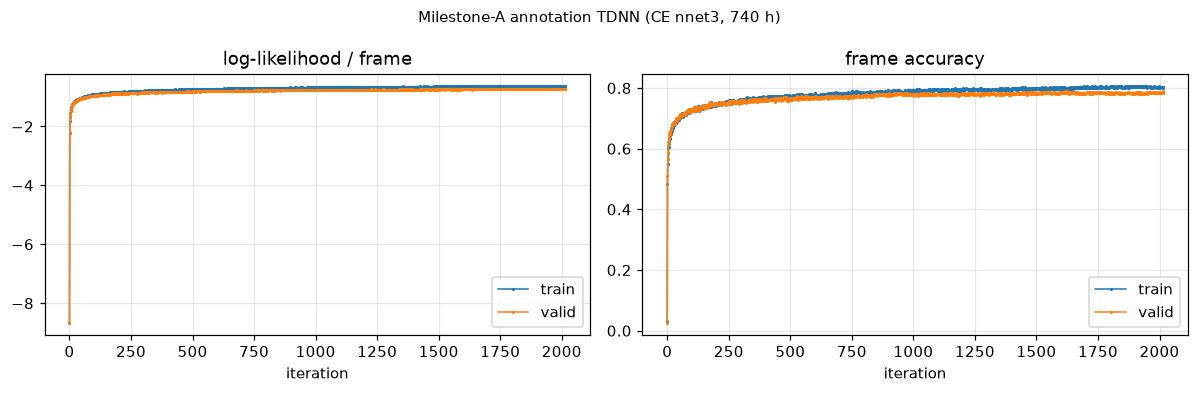

In [7]:
# Figure — milestone-A TDNN training curve (live from nnet3 diagnostic logs)
import re, glob
logdir = ROOT / 'exp/kaldi_pilot/exp/nnet3/tdnn_a/log'
LLp  = re.compile(r"log-likelihood for 'output' is (-?[0-9.]+) per frame")
ACCp = re.compile(r"accuracy for 'output' is (-?[0-9.]+) per frame")
def series(split, pat):
    pts = []
    for f in glob.glob(str(logdir / f'compute_prob_{split}.*.log')):
        m = re.search(rf'compute_prob_{split}\.(\d+)\.log$', f)
        if not m: continue
        hit = pat.search(open(f, encoding='utf-8', errors='ignore').read())
        if hit: pts.append((int(m.group(1)), float(hit.group(1))))
    return sorted(pts)
if logdir.exists() and glob.glob(str(logdir / 'compute_prob_valid.*.log')):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
    for split, col in (('train', 'tab:blue'), ('valid', 'tab:orange')):
        ll, ac = series(split, LLp), series(split, ACCp)
        if ll: a1.plot(*zip(*ll), lw=1, marker='.', ms=2, label=split, color=col)
        if ac: a2.plot(*zip(*ac), lw=1, marker='.', ms=2, label=split, color=col)
    v = series('valid', ACCp)
    print(f'iters logged: {len(v)}; latest valid acc={v[-1][1]:.3f}' if v else 'no logs yet')
    a1.set_title('log-likelihood / frame'); a1.set_xlabel('iteration'); a1.legend(); a1.grid(alpha=.3)
    a2.set_title('frame accuracy'); a2.set_xlabel('iteration'); a2.legend(); a2.grid(alpha=.3)
    fig.suptitle('Milestone-A annotation TDNN (CE nnet3, 740 h)', fontsize=10)
    fig.tight_layout(); plt.show()
else:
    print('TDNN logs not present in this tree (milestone-A stage 6 not run here)')

**Acceptance (F5) + harvest (milestone A, 2026-07-16).** TDNN alignment of
the 740 h cleaned set + `get_prons` yielded **1,896,791 stress-labeled tokens**
(43,302 word types, **139 phone-map mismatches = 0.007 %** — alignment and lang
fully consistent), up from the 1.22 M pilot harvest →
`stress_labels_milestone_a.jsonl`.

*Battery homographs* all resolve to a clear, sense-correct majority:
вълна́(wave) 79 %, па́ра(steam) 83 %, гово́ри(3sg) 94 %, чета́(verb) 80 %,
коса́(hair) 99 %, пра́ви(3sg) 98 %, но́си(3sg) 99 %, у́чи(3sg) 85 %,
хо́ди(3sg) 98 %, мо́ли(3sg) 96 %, ку́пи(aor) 84 % — with every minority
reading still attested (the counts the Accentor learns from).

*F5 acceptance is word-by-word, not all-or-nothing* — which is exactly what the
gate is for. The TDNN **corrected** the GMM bias on part of the tier-2 set
(мо́же 59 %, вси́чки 53 %, ве́че 93 %, ме́жду 91 %, вси́чко 75 %, не́го 96 %
→ canonical majority, promotable to tier-1 supervision), but **did not** on the
prosodically-unstable weak words (като́ 62 %, други́ 59 %, били́ 86 % remain
non-canonical), which therefore stay on the tier-2 exclusion / inference-
suppression list. Some promotions are narrow (вси́чки 53 %, и́ли 51 %) and,
with the three inversions, gate on a native spot-vet (`vet_stress_cli.py`)
before the promote/exclude split is trusted for ft6. Net: the milestone
delivered the highest-quality, largest label set to date and a measured,
per-word tier map — the acoustic-data-volume bottleneck (F12) is now addressed
on the *label* side; the residual is the front-end (ft6) and TTS rendering.

**Native re-vetting of the F5 words (2026-07-16, 212 clips, `vet_stress_cli.py`).** Each of the seven uncertain words turned out **effectively single-stress in the audio** — one variant ~100% reliable, the other ~0–33% (aligner noise) — so none is a contextual homograph. The split resolved by **word class**, correcting the harvest-majority reading of *други* (its majority други́ 59% was inverted noise; audio is a clean дру́ги 100% — a textbook F3 inversion only native listening reveals):
- **Promote to tier-1** (content words, real lexical stress, veto removes the noise): всички→вси́чки, други→дру́ги, може→мо́же.
- **Keep suppressed** (proclitic function words — the high-scoring variant is *phrasal prominence leaking to the next stressed word*, not lexical stress; confirmed by 8–11 'unsure' judgments each): като, между, или. (This repeats the earlier `като́ 10/10 / ка́то 0/9` trap.)
- *били* (participle) is a plausible genuine homograph (били́ 100% vs би́ли 33%); the per-token veto keeps its reliable reading.
The 212-clip verdicts append to `vetting_milestone_a.jsonl` and feed `build_accentor_finetune.py --vet-results` as a per-token veto; the tier lists were updated (може/всички promoted out of TIER2_EXCLUDE, като added). Lesson: on prosodically-weak words the aligner majority can invert, and audio vetting — not counts — is the arbiter (F3).


In [8]:
# Milestone-A harvest — live token/type count (if present)
f = ROOT / 'data/kaldi/stress_labels_milestone_a.jsonl'
if f.exists():
    import collections
    n = 0; types = set(); both = collections.defaultdict(collections.Counter)
    for line in open(f, encoding='utf-8'):
        r = json.loads(line); n += 1; w = r['word']; types.add(w)
        both[w][r['marked']] += 1
    split = {w: c for w, c in both.items() if len(c) > 1}
    print(f'{n:,} tokens, {len(types):,} word types, '
          f'{len(split):,} types with both stress variants observed')
else:
    print('milestone-A harvest not present in this tree')

1,896,791 tokens, 43,302 word types, 5,238 types with both stress variants observed


### 5.2 Label manufacturing: forced alignment with a GMM → TDNN aligner

The candidates lexicon (§5.1) offers the aligner every plausible stress reading
of each word; **forced alignment** then decides which one the narrator actually
produced, per spoken token. Concretely, Viterbi search over a
pronunciation-variant FST picks the single path whose acoustic scores best fit
the audio — and because the FST forks at each homograph (one branch through
`a1 r a0`, one through `a0 r a1`), choosing the best path *is* choosing the
stress. Those choices, aggregated, are our labels. The acoustic scores that
search relies on come from two models used in sequence.

**GMM (Gaussian Mixture Model)** — the classical acoustic model. Each 10 ms
frame is a ~13-dim MFCC vector; a phone (e.g. the stressed vowel `a1`) is
modelled as a mixture of Gaussians over that space, scoring how well a frame
matches. Non-neural, CPU-trained in hours, robust at modest scale, but each
phone is modelled largely context-free. We train the standard ladder
(`mono → tri1 → tri2b` [LDA+MLLT] `→ tri3b` [SAT/fMLLR]); this is what
produced the 1.22 M-token pilot harvest.

**TDNN (Time-Delay Neural Network)** — the neural refinement. Rather than
scoring each frame independently, a TDNN conditions on a *window of
neighbouring frames*, capturing context a per-phone GMM cannot (the vowel in
*мама* vs *врата*). It is trained not on raw audio but on the **GMM's own
alignments** as targets, and runs on GPU (milestone A, stage 6). We use a
cross-entropy (non-chain) TDNN deliberately: chain models subsample frames 3×,
which would destroy the 10 ms timestamp resolution the harvest needs.

**Why sequential.** The GMM bootstraps a robust, immediately usable alignment;
the TDNN, learning from it, sharpens the acoustic scores so the aligner's
а́-vs-а decision at each homograph is more reliable — cleaner labels for the
same audio. Forced alignment (the FST/Viterbi search) is identical under both;
only the scores it searches over improve. This is why the pipeline harvests
usable labels early (GMM) yet reserves a quality step (TDNN) for the final
milestone-A harvest that trains the deployed Accentor.

In [9]:
# Architecture self-check: parameter counts (ours vs paper-exact variant)
try:
    sys.path.insert(0, str(ROOT.resolve()))
    from accentor_model import Accentor, n_params
    ours = Accentor(); paper = Accentor(separable=True)
    print(f'ours (standard convs + caps): {n_params(ours)/1e6:.1f}M params')
    print(f'paper-exact (separable):      {n_params(paper)/1e6:.1f}M params')
except Exception as e:
    print('torch/model unavailable here:', e)

ours (standard convs + caps): 19.3M params
paper-exact (separable):      6.7M params


### 5.3 Pretrain objective and metrics (stage 3)

Trained on the masked dictionary-marked corpus (§4.1); batch 256, 100K steps, ~4.6 h on one 16 GB GPU. Deterministic held-out split: rows with `crc32(id) % 100 < 1` (~1%), **identical in pretrain and fine-tune** (no leakage between phases). Three metrics, all needed simultaneously:

- **`val_loss`** — masked BCE over labeled vowels only; the smooth optimization target and earliest overfitting signal. Not an accuracy.
- **`SER` (stress-error rate)** — the headline metric (Geneva et al.'s measure): over fully-labeled single-stress content words, the fraction where the argmax vowel is not the true stressed vowel. Hard 0/1 per word; reported with its denominator (~103K words in our val split).
- **`zero_err`** — spurious-stress rate on all-zero-labeled function words (a word errs if *any* vowel crosses 0.5). Kept separate from SER because the failure modes are asymmetric; this metric is what exposed the stressed-clitic dictionary bug.

Homograph accuracy is a **separate** evaluation (the battery, §6.2) — never merged into SER, because homographs are masked at pretrain and their val-split "truth" would be dictionary fiction.

### 5.4 Stress-aware forced alignment (stages 5–5b)

**Audiobook pilot (63 h, 37,299 utts).** Standard GMM ladder (mono → tri1 → tri2b LDA+MLLT → tri3b SAT → `align_fmllr`) over the stress-aware lexicon, dictionary **vocab-limited to the transcript** (the full 3.35M-pronunciation lexicon OOMs graph compilation at 2.6 GB × 24 jobs — §11). Health: final align log-prob ≈ −43.6, retry ≤ 2%, fail ≈ 1.3%.

**Parliament (long recordings).** Sessions are hours long; `steps/cleanup/segment_long_utterances.sh` bootstrap-decodes each session against a transcript-biased LM and emits matched segments, discarding mismatched regions. **Round 1** (audiobook-only GMMs as seed): 20% yield, 10–35% per-token noise — cross-domain seeding fails, as expected. **Round 2 (in-domain bootstrap)**: retrain the GMM ladder on audiobooks + round-1 segments, re-segment, re-align → **79% yield** (99.7 of 126.8 usable hours) and content-word noise at audiobook level (0.5–6.4%). This bootstrap iteration *is* the recipe for any new acoustic domain.

**Harvest.** `steps/get_prons.sh` extracts each token's chosen pronunciation; `harvest_stress_labels.py` joins it back to text → JSONL rows `{word, marked, sentence, audio_path, t0, dur, n_variants}` with segment-relative times mapped into the source recording (every label is *auditable by ear*). A >10% phone-map-mismatch guard protects against harvesting stale alignments through a rebuilt symbol table (§11).

### 5.5 Native vetting and the three-tier label policy (stage 5b)

GMM labels are noisy in a *structured* way. A native speaker audited ~190 tokens across 16 words with an interactive CLI (`vet_stress_cli.py`: plays the exact audio window of each label). Verdict: canonical-variant labels are ~95–100% accurate, and real contextual readings were confirmed (both гово́ри/говори́; both про́тив/проти́в — genuine variation). But the aligner shows a **systematic final-stress bias on prosodically weak words**, strong enough to invert corpus majorities: може́ outnumbered мо́же 1125:517 yet vetted 0/5 correct; всички́ 767:704, 0/6; съю́з ≈50:50, 0/7. These words *reduce* in fast speech; a forced binary stress choice there is partly meaningless.

The vetting calibrates a three-tier acceptance policy (`build_accentor_finetune.py`):

| Tier | Rule | Examples | Rationale |
|---|---|---|---|
| **1 — trust-canonical** | keep tokens matching canonical stress, iff the word is ≥90% canonical corpus-wide; drop minority tokens | тези, това, бъде, време | minority = aligner noise |
| **2 — exclude** | no stress supervision at all (treat as function words) | може, всички, съюз, вече, или | final-stress-bias signature |
| **3 — contextual gold** | keep **both** aligner readings | говори́/гово́ри, чета́/че́та, вълна́/въ́лна | vetting confirmed both occur |

**Design principle: humans calibrate, machines scale.** ~100 native judgments suffice because they calibrate a high-precision automatic labeler — they do not carry the training signal themselves (contrast RLHF, §10).

### 5.6 Both-readings text mining (stage 6e-bis)

The -и verb imperative/3sg alternation is **morphophonologically regular**: singular imperative is always final-stressed (говори́!, носи́!), 3sg present is root-stressed (гово́ри, но́си). Stress is rule-predictable once the *mood* is identified — so this class needs no audio, only imperative *contexts*, which literary dialogue has and parliament structurally lacks.

`mine_homographs.py` mines **both readings** with per-reading high-precision cues, skipping the ambiguous middle (a wrong label inverts a class — §7-F3):

- **3sg (root; abundant):** subject/subordinator before the verb (той/да/че/който…) or a proclitic (го носи); the да-subjunctive cue is dominant and near-100% precise;
- **imperative (final; sparse):** vocative/hortative particle before (хайде/недей/моля…); for *perfective* verbs also clause-initial in a short `!` clause;
- **skip:** не/я before the verb; bare clause-initial `!` on an *imperfective* verb — the indignant/habitual 3sg exclamation ("Хо́ди по жени!") is surface-identical to the imperative and unlabelable by rule.

Only the target token is supervised; all other words are masked — a pure one-token teaching signal. Verb aspect gates the cues (perfective купи/скочи mine cleaner imperatives than durative imperfectives). Precision ~96% (native spot-check). Yields confirm the register claim: 3sg abundant (говори 2002, прави 2001), imperatives genuinely rare (говори 6, купи 3, most 0–2) — mining widens the funnel but cannot manufacture what dialogue does not contain.

**Scope caveat (state in the paper):** this augmentation exploits a *morphological* regularity; it does not generalize to lexically arbitrary *semantic* homographs (въ́лна/вълна́, па́ра/пара́), which still require speech labels at volume.

### 5.7 Fine-tune recipe and TTS integration (stages 6e–6f)

**Accentor fine-tune.** Weights initialize from the pretrain (`--init`: fresh optimizer, low-LR schedule — 10K steps, lr 1e-4); data = speech-labeled rows (three-tier policy) + mined contexts + a **5:1 chitanka retention anchor** (re-marked pretrain rows folded back in so the narrow speech set does not erode the general lexicon). `--balance-ratio`/`--balance-floor` cap root-reading dominance (§6.2, ft4). `best.pt` selects on val SER.

**TTS integration (marking consistency).** The acoustic model must be fine-tuned on text marked by *the same Accentor version served at inference*. Our first combined fine-tune violated this: it trained on an earlier Accentor's marks that contradicted the narrator's audio (като́ where she says ка́то), so the model learned a noisy mark→stress mapping — audibly, "the stress moves, but not correctly." The fix (`mark_tts_txts.py`) re-marks only the text side of the tokenized training shards with the current checkpoint (audio tokens untouched) and re-fine-tunes. `serve.py --accentor <ckpt>` then deploys the same checkpoint as the live front-end, with the human overrides JSON as final veto.


## 6. Experiments and results

### 6.1 Pretrain and fine-tune metrics

Eight training runs. Pretrains (100K steps): `accentor_text` (initial marking), `text2` (post и́/му́ function-word fix), `text3` (current, re-marked corpus). Fine-tunes (10K steps, from `text2`/`text3`): `ft1` (three-tier policy), `ft2` (+tier-3 -и verbs), `ft3` (+both-readings mining, unbalanced), `ft4` (+6:1 balance cap), `ft5` (full-400 h harvest: 1.22M audiobook tokens + parliament round-2; pre-flight vetting of 36 variants).


In [10]:
# Table 3 — best checkpoint per run (live from exp/*/metrics.jsonl)
EXPS = ['accentor_text', 'accentor_text2', 'accentor_text3',
        'accentor_ft', 'accentor_ft2', 'accentor_ft3', 'accentor_ft4', 'accentor_ft5', 'accentor_ft5b']
hdr = f"{'run':<16}{'step':>7}{'val_loss':>10}{'SER':>9}{'(n)':>10}{'zero_err':>10}{'(n)':>9}"
print(hdr); print('─' * len(hdr))
curves = {}
for e in EXPS:
    p = f'exp/{e}/metrics.jsonl'
    if not exists(p):
        print(f'{e:<16}   (missing)'); continue
    rows = jload(p)
    curves[e] = rows
    b = min((r for r in rows if 'ser' in r), key=lambda r: r['ser'])
    print(f"{e:<16}{b['step']:>7}{b['val_loss']:>10.5f}{b['ser']*100:>8.3f}%"
          f"{b['ser_n']:>10,}{b['zero_err']*100:>9.3f}%{b['zero_n']:>9,}")
print('\nNote: pretrain and fine-tune SER share the split rule but not the denominator')
print('(fine-tune val = the mixed fine-tune corpus). Battery accuracy is separate (§6.2).')

run                step  val_loss      SER       (n)  zero_err      (n)
───────────────────────────────────────────────────────────────────────
accentor_text     82000   0.00020   0.003%   116,608    0.005%   59,435
accentor_text2    82000   0.00010   0.002%   102,686    0.000%   66,273
accentor_text3    78000   0.00009   0.002%   102,743    0.000%   66,412
accentor_ft        6000   0.00064   0.023%    25,964    0.000%   16,620
accentor_ft2       3000   0.00054   0.020%    25,303    0.006%   16,308
accentor_ft3      10000   0.00087   0.039%    25,905    0.000%   16,472
accentor_ft4       5000   0.00100   0.039%    25,750    0.006%   16,472
accentor_ft5      10000   0.00058   0.025%    84,425    0.000%   53,872
accentor_ft5b     11000   0.00049   0.020%    84,954    0.000%   54,345

Note: pretrain and fine-tune SER share the split rule but not the denominator
(fine-tune val = the mixed fine-tune corpus). Battery accuracy is separate (§6.2).


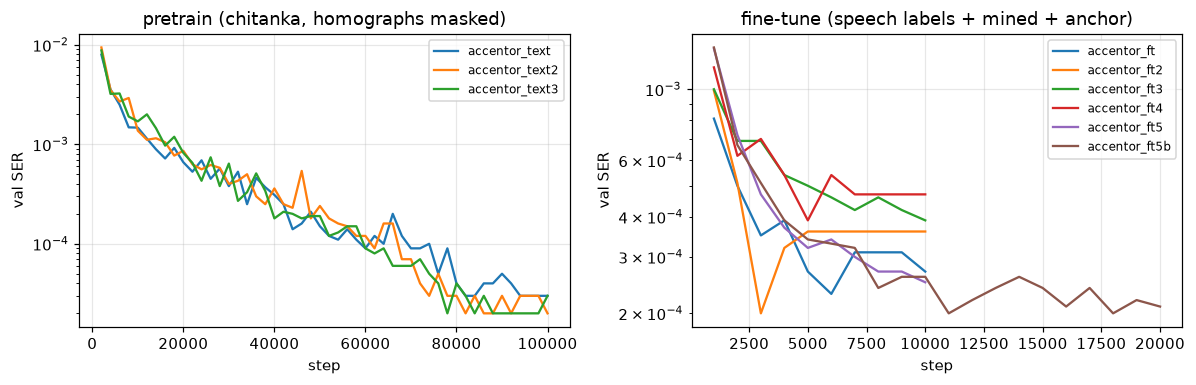

In [11]:
# Figure 1 — validation SER curves (log scale)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for e in ['accentor_text', 'accentor_text2', 'accentor_text3']:
    if e in curves:
        r = curves[e]
        axes[0].plot([x['step'] for x in r], [max(x['ser'], 1e-6) for x in r], label=e)
axes[0].set_title('pretrain (chitanka, homographs masked)')
for e in ['accentor_ft', 'accentor_ft2', 'accentor_ft3', 'accentor_ft4', 'accentor_ft5', 'accentor_ft5b']:
    if e in curves:
        r = curves[e]
        axes[1].plot([x['step'] for x in r], [max(x['ser'], 1e-6) for x in r], label=e)
axes[1].set_title('fine-tune (speech labels + mined + anchor)')
for ax in axes:
    ax.set_yscale('log'); ax.set_xlabel('step'); ax.set_ylabel('val SER')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 6.2 Homograph battery progression

The battery is a native-curated set of 25 sentences covering 13 homograph classes, each sentence forcing one reading by context. The text-only pretrain can learn at most one reading per form, so its score is the structural baseline. (Regenerate any row with `eval_accentor.py --ckpt exp/<run>/best.pt --battery config/bg/homograph_battery_sentences.json`.)

| checkpoint | battery | val SER | what changed |
|---|---|---|---|
| pretrain (text-only) | **11/25** | 0.003% | structural baseline: one reading per form |
| ft1 — three-tier speech labels | **12/25** | 0.023% | every *majority* reading learned at conf 1.00; every failure is a *minority* reading |
| ft2 — +tier-3 -и verbs | **12/25** | 0.020% | чета → 2/2 (≈balanced 19:9 tokens); купи → 0/2 (sparse noisy tokens *inverted* it) |
| ft3 — +both-readings mining | **12/25** | 0.039% | говори (141 mined imp.) & купи (perfective) → 2/2 — first imperative flips; all seven 3sg readings solid; two semantic classes regressed, offsetting |
| ft4 — +balance cap 6:1 | **13/25** | 0.039% | gains held; OOD SER unchanged after a 2000→300 3sg cut; **прави did not flip at 6:1** ⇒ absolute-count wall |
| ft5 — +full-400 h harvest (1.22M audiobook tokens), pre-flight vetting | **17/25** | 0.025% | прави́ flipped at ~99 contexts (wall ∈ [50,100]); ходи́ flipped at 3 speech tokens (cross-verb transfer); па́ра/че́та flipped; **чета́ INVERTED** — exactly as its 33%-vetted tokens predicted (F3 live); пара́ (24 tokens, at-floor) and само́ (drowned 100:1) vetted clean but did not flip |
| ft5b — per-token vetting veto (169 tokens dropped), 20K steps | **15–16/25**† | 0.020% | че́та tokens measured 19% precise (5/21/4) → vetoed; wild-text чета́ inversion FIXED (best.pt); пара 2/2 at step 20K (first ever); †battery oscillates ±2 between adjacent checkpoints — see §6.2.1 |

Per-class outcome at ft5: **solved** — all 3sg root readings, говори́/прави́/ходи́/купи́ imperatives, па́ра (steam), че́та (band), вълна́ (wave), коли́, за́мък; **unsolved** — imperatives with single-digit tokens (носи́ 9, учи́ 11, моли́ 7), pара́ (coin; at the ~20-token floor), само́ (100:1 imbalance), ко́са (adj., 8 tokens), въ́лна (wool); **inverted** — чета́ (noisy че́та tokens, vetted 33%, taught the boundary backwards — the fix is per-token vetting, not more data). Reporting rule: quote battery accuracy **split by majority vs minority reading** — the merged number hides exactly the phenomenon under study.


#### 6.2.1 Boundary oscillation and checkpoint selection

Classes with 20–100 training contexts sit on the decision boundary and flip between adjacent checkpoints of the *same* run: battery 17 (ft5 @10K) → 15 (ft5b @11K) → 16 (ft5b @20K), with пара changing direction twice, вълна swapping which two of three pass, and говори́/чета́ landing at 0.49–0.55 confidence. The stable core (all 3sg readings, прави́/ходи́/купи́ imperatives, коса́ hair, коли́, за́мък) never moves. **Checkpoint selection is blind to this**: `best.pt` selects on general val-SER, which excludes homographs by construction. The step-20K checkpoint scores +1 on the battery (пара 2/2) but regresses two *wild-text* reads on common words (че́та в медиите; "да си купи́ ваксина" where the да-subjunctive demands ку́пи); step-11K is wild-perfect. Serving therefore selects on wild-text homograph reads, not the battery alone — and the deployed stack keeps a human-overrides veto for the residue (промените, marked three different ways by three checkpoints against the native's проме́ните, is the type specimen). Remedies, in order of leverage: more distinct contexts per boundary class (milestone A); battery+wild pass-rate folded into checkpoint selection; never threshold tricks (no new signal).

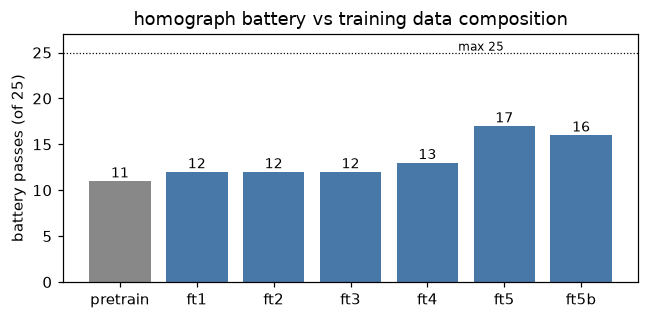

In [12]:
# Figure 2 — battery progression
runs = ['pretrain', 'ft1', 'ft2', 'ft3', 'ft4', 'ft5', 'ft5b']
scores = [11, 12, 12, 12, 13, 17, 16]
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(runs, scores, color=['#888'] + ['#4878a8'] * 6)
ax.axhline(25, ls=':', c='k', lw=0.8); ax.text(4.4, 25.2, 'max 25', fontsize=8)
ax.set_ylim(0, 27); ax.set_ylabel('battery passes (of 25)')
ax.set_title('homograph battery vs training data composition')
for b, s in zip(bars, scores):
    ax.text(b.get_x() + b.get_width()/2, s + 0.4, str(s), ha='center', fontsize=9)
plt.tight_layout(); plt.show()

In [13]:
# Table 4 — harvested homograph splits: both readings, from audio (live)
# Reproduces the minority-coverage evidence: counts of each marked variant
# chosen by the aligner for the battery homograph words.
WATCH = ['вълна', 'пара', 'чета', 'коса', 'само', 'боя', 'коли',
         'говори', 'носи', 'прави', 'учи', 'ходи', 'моли', 'купи', 'скочи']
counts = {w: collections.Counter() for w in WATCH}
n_read = 0
# ab400 = full 400h audiobook alignment (supersedes the 63h stress_labels.jsonl)
for p in ['data/kaldi/stress_labels_ab400.jsonl', 'data/kaldi/stress_labels_parliament2.jsonl']:
    if not exists(p): continue
    with open(ROOT / p, encoding='utf-8') as f:
        for line in f:
            r = json.loads(line); n_read += 1
            w = r.get('word', '')
            if w in counts:
                counts[w][r.get('marked', '')] += 1
print(f'scanned {n_read:,} aligned tokens (audiobooks + parliament round-2)\n')
print(f"{'word':<10} {'variant counts (aligner-chosen, from audio)'}")
print('─' * 64)
for w in WATCH:
    if counts[w]:
        s = '   '.join(f'{v} ×{c}' for v, c in counts[w].most_common())
        print(f'{w:<10} {s}')

scanned 1,426,758 aligned tokens (audiobooks + parliament round-2)

word       variant counts (aligner-chosen, from audio)
────────────────────────────────────────────────────────────────
вълна      вълна́ ×261   въ́лна ×77
пара       па́ра ×112   пара́ ×24
чета       чета́ ×51   че́та ×30
коса       коса́ ×644   ко́са ×8
само       са́мо ×10759   само́ ×101
боя        боя́ ×211   бо́я ×57
коли       коли́ ×169   ко́ли ×5
говори     гово́ри ×1130   говори́ ×90   го́вори ×3
носи       но́си ×457   носи́ ×9
прави      пра́ви ×1495   прави́ ×53
учи        у́чи ×118   учи́ ×11
ходи       хо́ди ×136   ходи́ ×3
моли       мо́ли ×126   моли́ ×7
купи       ку́пи ×130   купи́ ×16
скочи      ско́чи ×458


### 6.3 Out-of-domain generalization (parliament stenograms)

The train/val split is all chitanka *fiction*; parliamentary stenograms are formal political speech — different register, vocabulary, and syntax — making them a true generalization probe (`eval_accentor_ood.py`). Two measurements on unseen text:

1. **Automatic OOD SER:** for every *unambiguous* lexicon word in sampled stenogram sentences, compare the model's argmax vowel against the dictionary. Robust to sentence overlap (it scores dictionary words, not memorized sentences); deliberately excludes homographs (no automatic truth without audio).
2. **Homograph-in-the-wild:** model-marked natural sentences containing the homograph verbs, for native review.

| checkpoint | OOD SER | n words | func zero-err | mean conf |
|---|---|---|---|---|
| ft3 | **0.014%** | 14,251 | 0.000% | 1.000 |
| ft4 | **0.021%** | 19,026 | 0.011% (n=17,707) | 1.000 |

Essentially **no degradation from fiction to political speech** (val SER 0.020–0.039% → OOD 0.014–0.021%) — learned lexical stress transfers across register. In-the-wild homograph reads mirror the battery: говори/прави/чета/само/купи contextually correct (including чета́ as verb in "което Ви чета́"); носи/учи show the imperfective-imperative over-final error in the wild too, consistent with the coverage wall. Crucially, ft4's aggressive 3sg down-sampling (2000→300) did **not** move OOD SER — rebalancing is safe for the general lexicon.

### 6.4 Comparison with the reference system

| | Geneva et al. 2023 | this work (ft4) |
|---|---|---|
| aligned speech | 2,695 h (749 h AM) | ~550 h (450 audiobook + 99.7 parliament) |
| annotation AM | TDNN (auto-SER 0.119%) | GMM tri3b (pilot; TDNN at milestone A) |
| pretrain corpus | 48M tokens audiobooks + 22M parliament | 80M tokens chitanka (dictionary-marked) |
| SER (auto) | 0.119% | 0.002% val / 0.000–0.005% OOD¹ |
| homograph eval | (aggregate SER) | battery 15–17/25 (boundary oscillation ±2, §6.2.1), split by reading class |

¹ Not directly comparable: our auto-SER is dictionary-vs-model agreement on unambiguous words, theirs is TDNN-vs-model on all words including homographs. The honest comparison lands at milestone A when the annotation TDNN exists. What *is* new here: the per-reading-class breakdown, the coverage-wall quantification, and the vetting-calibrated tier policy — none reported in the reference.


## 7. Findings

**F1 — The minority-coverage wall.** After ft1, *every* battery failure was the minority reading of its class, with the majority reading at confidence 1.00. Corpus register is the cause: parliamentary and narration speech is overwhelmingly declarative 3rd-person, so imperative readings (говори́!, носи́!) structurally barely occur — the aligner captured every one it heard; the corpus just holds few. **Homograph accuracy is bounded by minority-reading coverage, and register systematically starves specific classes** (here the entire imperative/3sg alternation).

**F2 — The threshold is ~20 distinct balanced contexts per reading — and it is a floor, not a guarantee.** чета́/че́та, the one ~balanced class (19:9), went from a 0.51 coin-flip to a confident held-out PASS the moment it was supervised (ft2). At ft5, пара́ with exactly 24 vetted-clean tokens did NOT flip — sitting *at* the floor is insufficient; the miner's delivery spec is comfortably above ~20, and admission requires both count and precision (F3).

**F3 — Sparse noisy minority data is worse than none — and pre-training vetting *predicts* the damage.** купи entered tier-3 with sparse, subtle tokens (aorist vs imperative are segmentally identical) and the model learned both readings *backwards* (1/2 → 0/2, ft2). At ft5 the effect reproduced under controlled conditions: че́та tokens vetted 33% correct *before* training, and after training the class inverted exactly as predicted (че́та now passes, the previously-solid чета́ fails, with visible wavering on wild parliament text). Label acquisition must be gated on both count *and* precision — and a ~10-token native vet per admitted reading is a cheap, evidently reliable pre-flight.

**F4 — The imperative wall is absolute count, not class ratio — threshold now bounded in [50, 100] — with two amendments.** говори flipped with 141 distinct imperative contexts while still outnumbered; прави failed with 50 even rebalanced to 6:1 (ft4), then flipped at ~99 (46 vetted speech + 53 mined, ft5). **Reweighting is not new signal.** Amendment 1 (cross-verb transfer): ходи́ flipped at ft5 with only 3 speech tokens — once enough -и classes are solid (говори, прави, купи), the paradigm generalizes and per-class floors drop. Amendment 2 (extreme imbalance): само́ (101 clean tokens, 100:1 against) did not flip — beyond some imbalance, ratio re-enters; count dominance is a 6:1-regime result.

**F5 — GMM forced alignment has a systematic final-stress bias on prosodically weak words** — strong enough to invert corpus majorities (може́ 1125:517 vs vetted truth мо́же 0/5). These words genuinely destress/reduce in running speech (the native's 44% "unsure" rate on them is itself signal), so a forced binary label there is partly meaningless. Consequences: the tier-2 exclusion list, and a ready-made regression test for the annotation TDNN — its counts for може/всички/съюз must flip to the canonical majority, or it inherited the bias.

**F6 — Synthetic speech cannot label homographs.** BgTTS-38M, probed as a stress oracle, chose the frequency-prior reading regardless of context, consistently across seeds. Any TTS trained on unmarked text has *internalized* the prior we are trying to overcome; using it for labels is circular.

**F7 — Curated function words must outrank the dictionary.** rechko carries stressed clitic entries (и́, му́) that are wrong in running text; letting them through produced spurious clitic stress measurable in `zero_err`. The fix (curated list takes precedence) drove zero_err to 0.000% — and doubles as an example of why `zero_err` must be reported separately from SER.

**F8 — Cross-domain alignment needs one in-domain bootstrap round.** Audiobook-seeded segmentation of parliament yielded 20% with 10–35% label noise; one bootstrap iteration (retrain GMMs on audiobooks + round-1 segments, re-segment, re-align) recovered **79% yield at 0.5–6.4% noise**. This is the transferable recipe for any new acoustic domain.

**F9 — TTS marking consistency.** A TTS fine-tuned on marks that contradict its training audio learns a noisy mark→stress mapping — the stress *moves* under a mark, but incorrectly. Re-marking the training text with the deployed Accentor version fixed the imperative case audibly (§8). Corollary: every Accentor upgrade entails a TTS re-fine-tune (cheap: text side only, audio tokens reused).


**F10 — Transcript OOV structure is register-diagnostic and partially fixable.** On the full 400 h audiobook alignment, 33% of transcript types but only 5.6% of tokens were out-of-lexicon, splitting into narrated-fiction proper names (irreducible, ~3–4%) and hyphenated по-/най- comparatives (0.64% of tokens) — the latter a systematic lexicon gap recoverable by a prefix rule, pending a native convention for the double-stress problem (по́-добре́ vs the one-stress-per-word assumption). Measure the OOV top-k before any large alignment: systematic classes there are lexicon defects, not noise (§4.3).

**F11 — Boundary homograph classes oscillate between checkpoints, and standard checkpoint selection cannot see it.** Classes with 20–100 distinct contexts flip pass/fail between adjacent checkpoints of one run (battery 17→15→16 across ft5@10K/ft5b@11K/ft5b@20K; confidences 0.49–0.55 on the flippers), while the well-covered core never moves. `best.pt` selection by general val-SER excludes homographs by construction, so which side of the boundary ships is chance. Consequences: serve on wild-text homograph reads, not battery score; keep a human-overrides veto in the serving stack for the residue; and fold a homograph pass-rate into model selection. The veto-filter run (ft5b) also closed the loop on F3: with the 19%-precise че́та tokens removed, the wild-text inversion disappeared at the served checkpoint — per-token native vetting is both diagnostic *and* cure.

**F12 — Acoustic volume saturates before mark obedience (63 h → 413 h).** Eval loss
3.88 → 3.43, stress-rendering fidelity by ear ~unchanged: once the mark→acoustics
mapping is learned, more clean data reinforces the prior, not the instruction (§8.1).

**F13 — The sampling distribution contains what the argmax refuses, and the aligner
judge finds all of it.** Best-of-8 under serve-time decoding: 12/27 → 19/27 = oracle;
the label-manufacturing aligner, re-aimed at TTS output, is a *perfect selector* on
judgeable words (§8.2).

**F14 — Judged failures decompose into four diseases with four different cures.**
Sampling variance (selection), prior dominance (preference training; per-word, not
per-class), front-end errors exposed by unanimous disobedience (the pipeline audits
itself backwards — an obedience score is not a correctness score until the marks are
vetted), and single-variant errors outside the judge's sight (coverage) (§8.2).


## 8. End-to-end TTS evaluation

The full relay was exercised twice on the combined corpus (audiobook narrator + 50 h audiobook-clip slice):

- **Phase A (old marks — the control, inadvertently).** OmniVoice-BG fine-tuned on text marked by an early Accentor whose errors contradicted the audio (като́ vs the narrator's ка́то). Listening result: the model **does obey U+0301** (moving the mark audibly moves the stress) but renders it incorrectly — direct audible evidence of F9.
- **Phase B (re-marked with ft4, `mark_tts_txts.py`, re-fine-tuned = `exp/omnivoice_bg_ft4`).** The minimal-pair test *"Той гово́ри тихо."* / *"Говори́ по-високо!"*: the imperative говори́ now renders **correctly with clear final stress**; the 3sg reading shows a residual off-by-one-vowel error (го́вори for гово́ри) — placement is right in the *text*, the acoustic rendering is imprecise, consistent with limited fine-tune audio rather than front-end error.

**Planned formal protocol (TODO before submission):** minimal-pair intelligibility test (N homograph pairs × 2 readings, native forced-choice identification of intended reading from audio alone), plus standard MOS, plus the automatic verifier battery of §10 (aligner-measured stress obedience, Whisper CER, speaker similarity, UTMOS).

**Serving.** `serve.py` hosts the relay behind `POST /synth` (FastAPI, LAN): plain text → Accentor (`--accentor`, CPU, few ms) → marked text → OmniVoice-BG (GPU, fixed-reference deterministic cloning, seeded) → 24 kHz WAV. `/health` reports the active `accent_frontend`. The TrainGen video generator consumes it as a thin client.


### 8.1 Acoustic-volume scale-up: 63 h → 413 h (F12)

After marking consistency saturated (ft4 → ft5b A/B: no audible change), the remaining
hypothesis for imprecise stress rendering was acoustic data volume: the TTS had been
fine-tuned on 63 h while ~400 h of the same narrator sat on disk. We tokenized the full
corpus (448.3 h train / 4.5 h dev after length filtering, Higgs V2 codec, ft5b-marked
twin transcripts) and re-ran the fine-tune at 10 K steps (4:1 marked:unmarked mix,
init = the 63 h base checkpoint, lr 5e-6 cosine).

**Result:** eval loss moved decisively — 3.8809 (63 h run's endpoint) → **3.4315**
(best, step 6500) — but by-ear stress-rendering fidelity on the 28-sentence border set
barely moved. *(Caveat: the two runs use different dev sets — the honest comparison is
the A/B listening + the §8.2 oracle, not the raw losses.)* **Finding F12: once the
mark→acoustics mapping is learned, additional clean data reinforces the model's prior,
not its obedience to the instruction.** This redirected the effort from data volume to
sampling/selection (§8.2) and preference training (RAFT, planned).

20 evals every 500 steps; 63 h baseline endpoint: 3.8809 (ft5b run)
best: 3.4315 @ step 6500   final: 3.4341 @ 10000


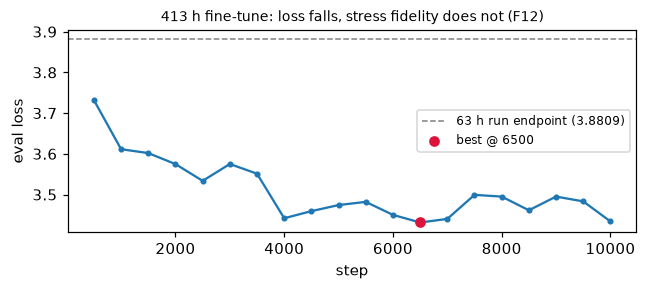

In [14]:
# Table 5 — full-corpus (413 h) fine-tune eval-loss trajectory (live from train.log)
import re
evals = []
for line in open(ROOT / 'exp/omnivoice_bg_full/train.log', encoding='utf-8'):
    m = re.search(r'Eval Loss: ([0-9.]+)', line)
    if m: evals.append(float(m.group(1)))
steps = [500 * (i + 1) for i in range(len(evals))]
best_i = min(range(len(evals)), key=lambda i: evals[i])
print(f'{len(evals)} evals every 500 steps; 63 h baseline endpoint: 3.8809 (ft5b run)')
print(f'best: {evals[best_i]:.4f} @ step {steps[best_i]}   final: {evals[-1]:.4f} @ {steps[-1]}')
plt.figure(figsize=(6, 2.6))
plt.plot(steps, evals, marker='o', ms=3)
plt.axhline(3.8809, ls='--', lw=1, color='gray', label='63 h run endpoint (3.8809)')
plt.scatter([steps[best_i]], [evals[best_i]], zorder=5, color='crimson', label=f'best @ {steps[best_i]}')
plt.xlabel('step'); plt.ylabel('eval loss'); plt.legend(fontsize=8); plt.tight_layout()
plt.title('413 h fine-tune: loss falls, stress fidelity does not (F12)', fontsize=9)
plt.show()

### 8.2 Best-of-N oracle: the aligner as judge (F13, F14)

If more data cannot force mark obedience, does the *sampling distribution* at least
contain obedient renderings? For each border sentence we generated **8 candidates**
from the best 413 h checkpoint under exact serve-time decoding — only the seed varies
(`position_temperature=5.0` randomizes the diffusion unmasking order) — then
force-aligned every candidate with the same stress-aware aligner that manufactured the
training labels (§4), now acting as a **judge**: which stress variant did each
candidate actually render?

Three numbers decide the ladder (recomputed live below):

- **single-sample** (candidate 0 = today's serving behavior): 12/27 sentences fully correct
- **judge-picked best-of-8**: 19/27
- **oracle** (any candidate correct): 19/27 — *the judge captures 100 % of the selection headroom* (F13)

The 8 unrecoverable sentences decompose into distinct failure classes (F14):
**(A)** sampling variance — recovered by selection; **(B)** *prior dominance* — correctly
marked rare readings (final-stress imperatives прави́, ходи́; пеша́, сгреши́, въ́лна)
that **all 8** candidates refuse, per-word rather than per-class (учи́ imperative renders
8/8 while ходи́ renders 0/8); **(C)** *Accentor errors the TTS unanimously corrected* —
пара́ marked for steam, чета́ for the noun, у́чи for the imperative: when all 8
candidates contradict a mark whose prior reading is right, the experiment has audited
the **front-end**, not the TTS. A judged pipeline audits itself in both directions, and
a judged score is an *obedience* score — reporting it as correctness requires the marks
be vetted first; **(D)** stress errors on single-variant words, invisible to a judge
that only adjudicates multi-variant lexicon entries (fix: an all-variant judge-only
lexicon, planned).

In [15]:
# Table 6 — best-of-N oracle, recomputed from bon_eval/bon_scores.jsonl (live)
rows = jload('bon_eval/bon_scores.jsonl')
by_sent = collections.defaultdict(list)
for r in rows: by_sent[r['sent_idx']].append(r)
for c in by_sent.values(): c.sort(key=lambda r: r['cand_idx'])
scored = {si: c for si, c in by_sent.items() if c[0]['n_targets']}
single = sum(c[0]['n_match'] == c[0]['n_targets'] for c in scored.values())
best   = sum(max(x['n_match'] for x in c) == c[0]['n_targets'] for c in scored.values())
oracle = sum(any(x['n_match'] == x['n_targets'] for x in c) for c in scored.values())
print(f'sentences with judgeable targets: {len(scored)}')
print(f'  single-sample : {single}/{len(scored)}')
print(f'  judge best-of-8: {best}/{len(scored)}')
print(f'  oracle         : {oracle}/{len(scored)}  (judge = oracle -> selection headroom fully captured)')
# hardest targets: 0/8 obedience (classes B and C mixed -- see decomposition above)
print('\n0/8 targets (all candidates contradict the mark):')
fail = collections.Counter()
for c in scored.values():
    for k in range(c[0]['n_targets']):
        if not any(x['targets'][k]['ok'] for x in c):
            t = c[0]['targets'][k]
            fail[(t['word'], t['want'])] += 1
for (w, want), n in sorted(fail.items()):
    print(f'  {w:<12} wanted {want}')

sentences with judgeable targets: 27
  single-sample : 12/27
  judge best-of-8: 19/27
  oracle         : 19/27  (judge = oracle -> selection headroom fully captured)

0/8 targets (all candidates contradict the mark):
  ако          wanted ако́
  между        wanted между́
  още          wanted още́
  пара         wanted пара́
  прави        wanted прави́
  сгреши       wanted сгреши́
  учи          wanted у́чи
  ходи         wanted ходи́
  чета         wanted чета́


### 8.3 Can a text LLM replace the audio pipeline? The BgGPT experiment (L17a)

A natural question: with strong Bulgarian LLMs available (INSAIT's BgGPT-Gemma-3-27B),
could contextual stress prediction be delegated to one, skipping the alignment pipeline
entirely? Two prompting regimes on the same border items, same model
(`Q4_K_M`, llama.cpp, temperature 0):

| regime | task given to the LLM | score |
|---|---|---|
| direct stress notation | "answer with the correctly stressed form (U+0301)" | **15/28** — context-blind, one fixed answer per word type, sometimes the wrong one (моли́, ко́са for hair, си́нът) |
| sense disambiguation | "which interpretation holds here: (а) аорист (б) повелително?" — glossed options, *our lexicon* maps the chosen sense to the mark | **12/12** on the identical items the first regime failed |

**The asymmetry is structural, not a prompting accident: Bulgarian orthography never
writes stress, so no text-trained model can have learned a context→stress mapping —
but sense disambiguation is exactly what a text LLM is made of.** (Finding L17a: route
phonology through semantics.) This validates a **teacher** pipeline that converts
unlimited chitanka *text* into Accentor training rows — the scale substitute for the
reference paper's 11,000 h of audio: sentence → LLM sense decision (few-token, glossed
options from a curated per-homograph *sense inventory*) → lexicon mark → training row,
with `source` provenance so the stream can be ablated wholesale, and audio-derived
labels remaining the sole ground truth (the circularity rule: never train a judge on
the front-end's own predictions).

Pilot audit (native review of random samples): first pass 17/20 — the three errors
exposed да-clause confusion, a proper-name mining leak (Моли the character), and an
overly literal figurative-wave gloss; after gloss + miner fixes and a **double-check
vote** (each item asked twice with reversed option order, disagreements rejected),
the second pass audited **20/20 clean** at 93 % acceptance.

#### 8.3.1 Inside the teacher: anatomy of one labeling cycle

The teacher (`bggpt_teacher.py`) converts raw book text into stress-labeled training
rows without the LLM ever seeing a stress mark. One cycle, run ~7,700 times per sweep:

**Step 1 — mining.** From the chitanka corpus (novels, cleaned), 600 sentences are
mined per homograph, with two hygiene filters learned from the pilot audit: length
bounds, and a *proper-name guard* — a match that appears only capitalized
mid-sentence is discarded (the pilot caught „— Предполагам… — **Моли** въздъхна
тихо" being labeled as the verb моля when Моли is a character's name; sentence-initial
capitals are kept because that position is where imperatives live).

**Step 2 — a sense question, not a stress question.** The LLM receives the sentence
and glossed interpretations from the curated *sense inventory*
(`config/bg/sense_inventory.json`):

> Изречение: „Мизерията им не спирала неговия старец да **ходи** по други жени."
> Дума: „ходи"
> а) сегашно време, 3 л. ед.ч. — включително след „да" (обича да ходи)
> б) повелително наклонение (ходи по-бързо!) ИЛИ минало свършено време

It answers with a single letter (temperature 0, ≤6 tokens): **а**. The glosses encode
hard-won linguistic detail: the „включително след 'да'" clause exists because the
pilot showed the LLM misreading да-constructions as imperatives; the вълна́ gloss
covers figurative waves (вълна от паника) because the literal-only gloss mislabeled
them; and the inventory encodes the perfective/imperfective asymmetry (aorist ку́пи
stresses the root, aorist ходи́ the ending) that a naive rule would corrupt.

**Step 3 — the double-check vote.** The same question is asked again with the options
presented in reverse order under swapped letters. Only if both answers select the same
*underlying sense* does the row survive; disagreement lands in a rejects file. This
cancels position bias and coin-flip answers at 2× query cost — steady ~6 % of items
are rejected, and the pilot's post-fix audit of survivors read 20/20 clean.

**Step 4 — the lexicon, not the LLM, adds the stress.** Sense (а) of ходи maps to
**хо́ди** via the inventory. The division of labor is strict: the LLM contributes
*understanding* (the task text models are actually trained for), the lexicon
contributes *pronunciation* (the knowledge orthography never gave the LLM a chance to
learn — §8.3's 15/28 vs 12/12 result).

**Step 5 — a provenance-stamped row is banked:**
```json
{"word": "ходи", "sense": "а", "marked": "хо́ди",
 "sentence": "Мизерията им не спирала неговия старец да ходи по други жени.",
 "source": "bggpt-teacher"}
```
The `source` tag keeps the text-derived stream separable from audio-derived labels —
it can be ablated, audited, or withdrawn wholesale — and the circularity rule holds:
teacher rows train the *Accentor* only; they never enter the Kaldi label harvest or
any judge, which must stay anchored to audio.

**In one line:** *Kaldi heard how the words are pronounced, BgGPT reads what the words
mean, the lexicon connects the two, and the Accentor learns all of it.* The same
question format later serves as an offline **arbiter** — a third opinion on sentences
where the Accentor is uncertain — but never enters the serving path, whose latency
budget belongs to the 19.3 M-parameter Accentor alone.

**Full-sweep audit (2026-07-15).** The completed random sweep produced **7,145
accepted rows / 562 rejected (92.7 % acceptance)** across the 13 validated homographs.
A native review of a 50-row random sample scored **49/50 correct** (~98 % precision) —
well clear of the danger zone F3 identified (there, ~19 %-precise minority labels
*inverted* a class; 98 % does not). The distinctions held on subtle cases: *money* пара́
in „Голяма пара са това две хиляди" against literal-steam па́ра elsewhere, and all three
боя senses (fear-verb боя́ vs battle-noun бо́я) resolved correctly in the wild. The lone
error was idiomatic — „действаше **на пълна пара**" (at full steam) mislabeled as the
money sense — locating the residual failure mode precisely: **idioms**, where a
literal-sense gloss has no entry for the figurative reading. Rare and hard; a limitation
to note rather than engineer around, and the double-check already discards the cases
where the model itself wavers.

The histogram (Table 7) also confirmed the coverage prediction: random prose richly
covers noun/present/3sg senses (all 350–580 rows) but starves the six **imperatives**
(говори́ 18, прави́ 35, ходи́ 25, моли́ 9, купи́ 4, учи́ 7) plus the rarer само́ (4)
and the che-noun че́та (18) — below the F4 flip wall. This is not a teacher defect but a
property of narrative text (narration is overwhelmingly present/3sg), and it motivates a
**targeted round** (`--sentences data/chitanka/imperatives.jsonl`): pre-mined
imperative-position candidates, sense-confirmed by the same LLM, top up exactly those
classes (a dry run offers 228 говори + 214 прави + …). Two residual senses — че́та the
noun and само́ 'alone' — are not verb-imperatives and merge instead with the
audio-derived milestone-A harvest, which samples them from real speech.

**Imperative round + second audit (2026-07-15).** A targeted round over
pre-mined imperative-position candidates (`--sentences imperatives.jsonl`,
same sense-confirmation + double-check) added 482 rows at 83 % acceptance —
the lower rate than the random sweep's 93 % is the heuristic's noise being
caught: imperative-position candidates include 3sg-with-exclamation and
да-clauses, which the double-check rejects or the LLM correctly re-files as
present tense. Effect on the starved classes (cumulative, 7,720 rows total):
the two productive imperatives cleared the F4 wall — **говори́ 18→210,
прави́ 35→215** — while the smaller siblings (ходи́ 36, носи́ 29, купи́ 18,
моли́ 12) stay numerically short but are expected to ride cross-verb transfer
(F4 amendment: ходи́ flipped at 3 tokens once its family was supervised) now
that the pattern is richly anchored; учи́ (8), само́ 'alone' (4) and the
che-noun че́та (18) are deferred to the audio-derived harvest that samples
them from real speech.

A second 50-row native audit scored **49/50** again (~98 %), with the
imperative-round rows verified correct in the wild („Прави, каквото
правиш!" → прави́; „Говори с думите на демоните!" → говори́). The lone error
was „Докато не дойда, **не говори** с никого" labeled 3sg — a **negative
imperative** („не говори" = don't speak) mislabeled because it is
surface-identical to negated present („той не говори" = he doesn't speak),
distinguished only by the (absent) subject. Together the two audits
characterize the residual error surface as two ~2 % edge classes — **idioms**
(на пълна пара) and **negative imperatives** (не + verb) — both narrow.
*Noted future fix:* extend the imperative gloss in the sense inventory with a
negative example („или забрана: не говори!") before the ft6-prep re-mark;
untested, so deferred rather than applied.

In [16]:
# Live demonstration — real cycles from the CURRENT teacher stream (accepted + rejected)
if exists('data/bggpt_teacher/sense_rows.jsonl'):
    import random as _r
    rows = jload('data/bggpt_teacher/sense_rows.jsonl')
    _r.Random(7).shuffle(rows)
    print(f'accepted rows so far: {len(rows)}; three samples:')
    for r in rows[:3]:
        print(f"  [{r['word']} -> {r['marked']}]  {r['sentence'][:90]}")
    if exists('data/bggpt_teacher/sense_rows.jsonl.rejects'):
        rej = jload('data/bggpt_teacher/sense_rows.jsonl.rejects')
        dis = [x for x in rej if x.get('answer') == 'disagreement/invalid']
        print(f'\nrejected so far: {len(rej)} ({len(dis)} double-check disagreements); two samples:')
        for x in dis[:2]:
            print(f"  [{x['word']}]  {x['sentence'][:90]}")
else:
    print('teacher stream not generated yet')

accepted rows so far: 7720; three samples:
  [само -> са́мо]  Винаги му беше по-лесно да избута на безопасно разстояние встрани въпросите, свързани с Го
  [вълна -> вълна́]  Тя бе стиснала зъби, докато той я обладаваше, отнесена от една вълна на страдание и удовол
  [боя -> бо́я]  А всеки един от хилядите там имаше своя мисъл, усещаше по свой, неповторим начин боя за Ви

rejected so far: 667 (667 double-check disagreements); two samples:
  [ходи]  Когато Хармън се надигна да си ходи, Чарли се изправи и му протегна ръка.
  [купи]  — Обиколи магазините наоколо и купи чайник, кафеварка и дванайсет чаши — тя видя как погле


In [17]:
# Table 7 — BgGPT teacher stream: per-sense yield (live; grows as the teacher runs)
if exists('data/bggpt_teacher/sense_rows.jsonl'):
    trows = jload('data/bggpt_teacher/sense_rows.jsonl')
    rej = 0
    if exists('data/bggpt_teacher/sense_rows.jsonl.rejects'):
        rej = len(jload('data/bggpt_teacher/sense_rows.jsonl.rejects'))
    hist = collections.Counter(r['marked'] for r in trows)
    print(f'{len(trows)} accepted rows, {rej} rejected (double-check disagreements etc.)')
    for m, c in sorted(hist.items(), key=lambda kv: -kv[1]):
        print(f'  {m:<14} {c}')
else:
    print('teacher stream not generated yet (bggpt_teacher.py)')

7720 accepted rows, 667 rejected (double-check disagreements etc.)
  но́си          590
  чета́          582
  у́чи           580
  гово́ри        545
  ку́пи          544
  са́мо          539
  вълна́         526
  хо́ди          513
  пра́ви         511
  боя́           496
  проме́ните     463
  мо́ли          415
  па́ра          365
  прави́         215
  говори́        210
  пара́          202
  промени́те     127
  бо́я           100
  въ́лна         72
  ходи́          36
  носи́          29
  че́та          18
  купи́          18
  моли́          12
  учи́           8
  само́          4


## 9. Limitations

1. **GMM-grade labels.** All current speech labels come from the pilot GMM aligner; the paper's trusted annotator is a TDNN (auto-SER 0.119%). Tier policy contains the damage but cannot recover tier-2 words. Milestone A replaces this.
2. **Scale.** ~163 aligned hours vs the reference's 2,695; low-frequency homograph classes (моли́: 0 tokens) are simply unobserved.
3. **Semantic homographs remain data-bound.** Mining (C4) covers only the morphologically regular alternation; въ́лна/вълна́-type pairs need speech volume.
4. **The battery is small** (25 sentences) — a per-class diagnostic, not a statistical benchmark. The in-the-wild protocol scales it but requires native review.
5. **OOD SER measures dictionary agreement**, so it inherits dictionary errors and excludes homographs by construction; it is a transfer probe, not an absolute accuracy.
6. **Single-voice TTS evaluation.** Phase-B listening is one narrator; stress-rendering fidelity under zero-shot cloning of arbitrary voices is untested.
7. **Text normalization is out of scope** — numbers/dates in stenograms are dropped (their audio regions are discarded at segmentation), and the serving path does not verbalize numerals.


## 10. Future work

- **Milestone A (~500 h raw parliament):** annotation TDNN on audiobooks + parliament (≈ the paper's 749 h recipe), with the F5 bias test as its acceptance gate; then per-sentence stress decoding over the whole corpus → BG-PARLAMA-scale label set; 400 h audiobook ingest (in progress) adds narrated *dialogue* — the register that carries spoken imperatives.
- **Class-balanced sampling** once mining + milestone A provide enough distinct minority contexts for upweighting to generalize (F4 gate).
- **Preference-optimization polish for the TTS** (explored, deliberately sequenced last): the project already owns automatic verifiers — the stress-aware aligner (does the audio realize its marks?), Whisper CER, speaker similarity, UTMOS — so the practical form is RLAIF, not RLHF. Ladder: best-of-N at inference (ships anytime, zero training) → best-of-N distillation / RAFT (reuses the ordinary trainer; the recommended target) → Diffusion-DPO variants (log-probs are intractable in a mask-prediction LM; ELBO proxy needed) → online PPO/GRPO (rejected on 16 GB hardware). Principle: *humans calibrate verifiers; machines scale supervision* — RL polishes residuals only after the supervised loop lands.
- **Release:** candidates lexicon, battery, mined contexts, label-harvest tooling, and the Accentor checkpoints, license permitting (rechko terms to verify).
- **A modern k2 stack for the ASR byproduct (Zipformer/icefall).** The milestone-A TDNN is retained for *label manufacturing* — forced alignment is transcript-constrained (F2), and its bounded context gives sharper 10 ms boundaries than an LSTM or Transformer, which the stress harvest needs. But the free-decoding **ASR byproduct** favours a **Zipformer in icefall/k2** (k2-fsa also builds OmniVoice, so Zipformer-ASR + OmniVoice-TTS is a coherent stack); the 740 h cleaned/aligned corpus + 115 K lexicon port directly, needing only an added LM. A framework port, worthwhile only if the ASR is pursued as its own deliverable.


## 11. Reproducibility

**Hardware.** Single workstation: 24 cores, 60 GB RAM (+8 GB swap), one 16 GB GPU, NVMe. Every stage fits; the constraints are themselves documented findings (vocab-limited lexicon compilation after an OOM that masqueraded as a power failure; `seg_nj=8` for segmentation memory; `expandable_segments` for the TTS fine-tune).

**Pipeline commands (one line per stage).**

```bash
# 1. lexicon: rechko dump -> candidates DB -> stress-aware phonetic lexicon
python build_bg_lexicon.py --dump ../rechko/db.sql --out data/bg_lexicon/bg_stress.sqlite
python build_stress_candidates.py --src ... --battery config/bg/homograph_battery.json --out ... --validate
python build_lexicon_phones.py --cand ... --out-lexicon data/bg_lexicon/lexicon_full.txt

# 2. pretrain corpus
python prep_chitanka.py --archive data/chitanka_archive --out data/chitanka
python mark_chitanka_text.py --corpus data/chitanka --sqlite ...candidates.sqlite --out data/chitanka/marked.jsonl

# 3. Accentor pretrain (~4.6 h, 16 GB GPU)
python train_accentor.py --data data/chitanka/marked.jsonl --out exp/accentor_text3

# 4. corpora: parliament crawl + audiobook ingest
python prep_bg_parliament.py --out data/bg_parliament --date-start 2020-01-01 --date-end 2026-12-31 --reverse
python prep_bg400.py --out data/bg400 --max-hours 500

# 5. stress-aware alignment + label harvest
KALDI_ROOT=~/kaldi bash kaldi_pilot.sh                 # audiobooks: GMM ladder + align
KALDI_ROOT=~/kaldi bash kaldi_parliament_pilot.sh      # parliament: segment + bootstrap + align
python harvest_stress_labels.py --pilot exp/kaldi_pilot --ali exp/tri3b_ali --out data/kaldi/stress_labels.jsonl

# 6. vet, mine, fine-tune, evaluate
python vet_stress_cli.py --labels data/kaldi/stress_labels_parliament2.jsonl   # native audit
python mine_homographs.py --corpus data/chitanka --verbs config/bg/homograph_verbs.json --out data/chitanka/homograph_contexts.jsonl
python build_accentor_finetune.py --labels ... --extra-marked ... --mix-chitanka ... --balance-ratio 4 --balance-floor 300 --out data/accentor_finetune.jsonl
python train_accentor.py --data data/accentor_finetune.jsonl --init exp/accentor_text3/best.pt --out exp/accentor_ft4 --steps 10000 --lr 1e-4
python eval_accentor.py --ckpt exp/accentor_ft4/best.pt --battery config/bg/homograph_battery_sentences.json
python eval_accentor_ood.py --ckpt exp/accentor_ft4/best.pt --transcripts data/bg_parliament/transcripts --n 4000

# 7. TTS: re-mark training text with the deployed Accentor, re-fine-tune, serve
python mark_tts_txts.py --ckpt exp/accentor_ft4/best.pt --dirs data/bg/tokens/train data/bg/tokens/dev ...
accelerate launch --gpu_ids 0 --num_processes 1 -m omnivoice.cli.train --train_config config/bg/train_config_bg_marked.json ...
python -m omnivoice.cli.serve --model models/omnivoice-bg --accentor exp/accentor_ft4/best.pt --host 0.0.0.0 --port 8002 --seed 42
```

**Key repository files.**

| Component | Files |
|---|---|
| Lexicon | `build_bg_lexicon.py`, `build_stress_candidates.py`, `build_lexicon_phones.py`, `config/bg/always_final_imperatives.json` |
| Corpus + marking | `prep_chitanka.py`, `mark_chitanka_text.py`, `prep_bg_parliament.py`, `bg_sten_clean.py`, `prep_bg400.py` |
| Accentor | `accentor_model.py`, `train_accentor.py`, `eval_accentor.py`, `eval_accentor_ood.py` |
| Alignment + labels | `prep_kaldi_data.py`, `kaldi_pilot.sh`, `kaldi_parliament_pilot.sh`, `harvest_stress_labels.py`, `vet_stress_cli.py` |
| Mining + fine-tune | `mine_homographs.py`, `config/bg/homograph_verbs.json`, `build_accentor_finetune.py` |
| TTS + serving | `mark_tts_txts.py`, `omnivoice/cli/serve.py`, `serve_bg.sh`, `eval_bg_ab.py` |
| Curation (native) | `config/bg/homograph_battery*.json`, `config/bg/function_words_unstressed.json`, `config/bg/lexicon_supplement.json` |

**Operational lessons** (full detail in `docs/BG_PIPELINE_GUIDE.md` §Pitfalls): budget `nj × per-job RSS` against RAM before any fan-out (an OOM kill of the desktop session is indistinguishable from a power failure until you read `journalctl`); `prons.*.gz` are only valid against the symbol tables they were written with (the harvester guards at >10% mismatch); never seek session FLACs with ffplay (no seektable — extract with ffmpeg, play via paplay).


## 12. References *(complete before submission)*

1. **Geneva et al., Interspeech 2023** — the Accentor: contextual lexical-stress prediction for Bulgarian; source of the architecture, the alignment-labeling method, and BG-PARLAMA. *(exact title/authors from `docs/interspeech2023.pdf`)*
2. **Virkkunen et al., 2022** — Finnish Parliament ASR corpus pipeline, arXiv:2203.14876 — reference for transcript-biased long-audio segmentation of plenary recordings.
3. **OmniVoice** (k2-fsa) — massively multilingual zero-shot TTS; diffusion-LM over audio codec tokens. https://github.com/k2-fsa/OmniVoice
4. **Higgs Audio V2** — neural audio codec/tokenizer (8 codebooks, 24 kHz).
5. **Qwen3-0.6B** — text-LLM backbone of OmniVoice.
6. **Povey et al., 2011** — The Kaldi speech recognition toolkit, ASRU.
7. **Peddinti/Manohar et al.** — Kaldi `segment_long_utterances` / data-cleanup recipes for lightly-supervised alignment.
8. **rechko / chitanka** — Bulgarian dictionary (lemma stress) and digital library (text corpus). License terms to verify before artifact release.
9. **BgTTS-38M-V2** (beleata74) — compact end-to-end Bulgarian TTS; used here only as a negative-control stress oracle (F6).
10. **Ren et al., 2019/2021 — FastSpeech 1/2** — origin of the FFT-block architecture.
11. **RAFT / DPO / Diffusion-DPO** — preference-optimization methods surveyed for the planned TTS polish (§10).
